In [ ]:
# Phase 3 - Environment Setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import deque
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Environment ready ✅")

Environment ready ✅


In [ ]:
import random

def generate_loop_trace(length=500):
    pattern = ["A", "B", "C", "D", "E", "F"]
    return [pattern[i % len(pattern)] for i in range(length)]


def generate_sequential_trace(length=500):
    pattern = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
    return [pattern[i % len(pattern)] for i in range(length)]


def generate_random_trace(length=500, blocks=20):
    pattern = [chr(ord("A") + i) for i in range(blocks)]
    return [random.choice(pattern) for _ in range(length)]


loop_trace = generate_loop_trace()
seq_trace = generate_sequential_trace()
random_trace = generate_random_trace()

print("Loop trace:", loop_trace[:30])
print("Sequential trace:", seq_trace[:30])
print("Random trace:", random_trace[:30])

Loop trace: ['A', 'B', 'C', 'D', 'E', 'F', 'A', 'B', 'C', 'D', 'E', 'F', 'A', 'B', 'C', 'D', 'E', 'F', 'A', 'B', 'C', 'D', 'E', 'F', 'A', 'B', 'C', 'D', 'E', 'F']
Sequential trace: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'A', 'B', 'C', 'D']
Random trace: ['H', 'D', 'Q', 'P', 'B', 'M', 'P', 'O', 'A', 'L', 'A', 'G', 'C', 'Q', 'R', 'A', 'H', 'R', 'I', 'T', 'Q', 'D', 'Q', 'B', 'E', 'I', 'O', 'B', 'L', 'G']


In [ ]:
def generate_dynamic_trace():
    loop_part = generate_loop_trace(300)
    random_part = generate_random_trace(300)
    seq_part = generate_sequential_trace(300)

    return loop_part + random_part + seq_part


dynamic_trace = generate_dynamic_trace()

print("Dynamic trace length:", len(dynamic_trace))
print("First 20:", dynamic_trace[:20])
print("Around phase 2:", dynamic_trace[295:315])
print("Around phase 3:", dynamic_trace[595:615])

Dynamic trace length: 900
First 20: ['A', 'B', 'C', 'D', 'E', 'F', 'A', 'B', 'C', 'D', 'E', 'F', 'A', 'B', 'C', 'D', 'E', 'F', 'A', 'B']
Around phase 2: ['B', 'C', 'D', 'E', 'F', 'R', 'N', 'E', 'D', 'D', 'N', 'Q', 'A', 'C', 'M', 'C', 'O', 'O', 'A', 'C']
Around phase 3: ['Q', 'Q', 'H', 'D', 'D', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O']


In [ ]:
def create_replacement_dataset(trace, lookahead=8):
    rows = []

    last_access = {}
    frequency = {}

    for i, block in enumerate(trace):

        # Blocks seen so far
        seen_blocks = set(trace[:i])

        for candidate in seen_blocks:

            # Recency
            if candidate in last_access:
                recency = i - last_access[candidate]
            else:
                recency = i + 1

            # Frequency
            freq = frequency.get(candidate, 0)

            # Reuse distance
            if candidate in last_access:
                reuse_distance = i - last_access[candidate]
            else:
                reuse_distance = i + 1

            # Previous hit
            previous_access = trace[max(0, i-1):i]
            previous_hit = int(candidate in previous_access)

            # Recent pattern count
            recent_history = trace[max(0, i-5):i]
            recent_pattern = recent_history.count(candidate)

            # Cache age
            cache_age = recency

            # Look into the future ONLY to create the label
            future_window = trace[i + 1:i + 1 + lookahead]

            will_reuse_soon = int(candidate in future_window)

            rows.append({
                "recency": recency,
                "frequency": freq,
                "reuse_distance": reuse_distance,
                "recent_pattern": recent_pattern,
                "previous_hit": previous_hit,
                "cache_age": cache_age,
                "will_reuse_soon": will_reuse_soon
            })

        # Update history after feature extraction
        last_access[block] = i
        frequency[block] = frequency.get(block, 0) + 1

    return pd.DataFrame(rows)


replacement_df = create_replacement_dataset(dynamic_trace)

print("Dataset created successfully ✅")
print("Dataset shape:", replacement_df.shape)

print("\nFirst 10 rows:")
display(replacement_df.head(10))

print("\nLabel distribution:")
print(replacement_df["will_reuse_soon"].value_counts())

Dataset created successfully ✅
Dataset shape: (15108, 7)

First 10 rows:


,recency,frequency,reuse_distance,recent_pattern,previous_hit,cache_age,will_reuse_soon
0,1,1,1,1,1,1,1
1,2,1,2,1,0,2,1
2,1,1,1,1,1,1,1
3,1,1,1,1,1,1,1
4,3,1,3,1,0,3,1
5,2,1,2,1,0,2,1
6,2,1,2,1,0,2,1
7,4,1,4,1,0,4,1
8,3,1,3,1,0,3,1
9,1,1,1,1,1,1,1



Label distribution:
will_reuse_soon
0    9123
1    5985
Name: count, dtype: int64


In [ ]:
import random

def generate_dynamic_trace(seed, phase_length=300):
    rng = random.Random(seed)

    # Phase 1: looping
    loop_pattern = ["A", "B", "C", "D", "E", "F"]
    loop_part = [
        loop_pattern[i % len(loop_pattern)]
        for i in range(phase_length)
    ]

    # Phase 2: random
    random_blocks = [
        chr(ord("A") + i) for i in range(20)
    ]
    random_part = [
        rng.choice(random_blocks)
        for _ in range(phase_length)
    ]

    # Phase 3: sequential
    seq_pattern = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
    seq_part = [
        seq_pattern[i % len(seq_pattern)]
        for i in range(phase_length)
    ]

    return loop_part + random_part + seq_part


# Generate different traces
train_traces = [
    generate_dynamic_trace(seed)
    for seed in range(1, 21)
]

validation_traces = [
    generate_dynamic_trace(seed)
    for seed in range(21, 26)
]

test_traces = [
    generate_dynamic_trace(seed)
    for seed in range(26, 31)
]

print("Training traces   :", len(train_traces))
print("Validation traces:", len(validation_traces))
print("Test traces       :", len(test_traces))

Training traces   : 20
Validation traces: 5
Test traces       : 5


In [ ]:
train_dfs = []

for trace in train_traces:
    df = create_replacement_dataset(trace, lookahead=8)
    train_dfs.append(df)

train_df = pd.concat(train_dfs, ignore_index=True)


validation_dfs = []

for trace in validation_traces:
    df = create_replacement_dataset(trace, lookahead=8)
    validation_dfs.append(df)

validation_df = pd.concat(validation_dfs, ignore_index=True)


test_dfs = []

for trace in test_traces:
    df = create_replacement_dataset(trace, lookahead=8)
    test_dfs.append(df)

test_df = pd.concat(test_dfs, ignore_index=True)


print("Train shape      :", train_df.shape)
print("Validation shape :", validation_df.shape)
print("Test shape       :", test_df.shape)

Train shape      : (302879, 7)
Validation shape : (75827, 7)
Test shape       : (75973, 7)


In [ ]:
train_df.to_csv("replacement_train.csv", index=False)
validation_df.to_csv("replacement_validation.csv", index=False)
test_df.to_csv("replacement_test.csv", index=False)

print("Datasets saved ✅")

Datasets saved ✅


In [ ]:
feature_columns_v2 = [
    "recency",
    "frequency",
    "recent_frequency",
    "recent_frequency_ratio",
    "avg_reuse_distance",
    "reuse_distance_std",
    "lifetime",
    "recent_working_set_size"
]

X_train_v2 = train_v2[feature_columns_v2]
y_train_v2 = train_v2["will_reuse_soon"]

X_val_v2 = validation_v2[feature_columns_v2]
y_val_v2 = validation_v2["will_reuse_soon"]

X_test_v2 = test_v2[feature_columns_v2]
y_test_v2 = test_v2["will_reuse_soon"]

print("Training :", X_train_v2.shape)
print("Validation:", X_val_v2.shape)
print("Testing   :", X_test_v2.shape)

Training : (302879, 8)
Validation: (75827, 8)
Testing   : (75973, 8)


In [ ]:
model_v2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=14,
    min_samples_leaf=2,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

print("Training improved Random Forest...")

model_v2.fit(
    X_train_v2,
    y_train_v2
)

print("✅ Version 2 trained!")

Training improved Random Forest...
✅ Version 2 trained!


In [ ]:
importance_v2 = pd.Series(
    model_v2.feature_importances_,
    index=feature_columns_v2
).sort_values(ascending=False)

display(importance_v2)

,0
recency,0.266476
recent_working_set_size,0.237717
recent_frequency,0.149355
avg_reuse_distance,0.117202
recent_frequency_ratio,0.094769
lifetime,0.065448
reuse_distance_std,0.045269
frequency,0.023763


In [ ]:
model_v2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=14,
    min_samples_leaf=2,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

print("Training Version 2 Random Forest...")

model_v2.fit(X_train_v2, y_train_v2)

print("✅ Version 2 training completed!")

Training Version 2 Random Forest...
✅ Version 2 training completed!


In [ ]:
y_val_pred_v2 = model_v2.predict(X_val_v2)

val_accuracy_v2 = accuracy_score(y_val_v2, y_val_pred_v2)
val_precision_v2 = precision_score(y_val_v2, y_val_pred_v2)
val_recall_v2 = recall_score(y_val_v2, y_val_pred_v2)
val_f1_v2 = f1_score(y_val_v2, y_val_pred_v2)

print("VERSION 2 — VALIDATION")
print("----------------------")
print(f"Accuracy : {val_accuracy_v2:.4f}")
print(f"Precision: {val_precision_v2:.4f}")
print(f"Recall   : {val_recall_v2:.4f}")
print(f"F1 Score : {val_f1_v2:.4f}")

print("\nClassification Report:")
print(classification_report(y_val_v2, y_val_pred_v2))

VERSION 2 — VALIDATION
----------------------
Accuracy : 0.8541
Precision: 0.8960
Recall   : 0.7138
F1 Score : 0.7946

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.95      0.89     45845
           1       0.90      0.71      0.79     29982

    accuracy                           0.85     75827
   macro avg       0.87      0.83      0.84     75827
weighted avg       0.86      0.85      0.85     75827



In [ ]:
y_test_pred_v2 = model_v2.predict(X_test_v2)

test_accuracy_v2 = accuracy_score(y_test_v2, y_test_pred_v2)
test_precision_v2 = precision_score(y_test_v2, y_test_pred_v2)
test_recall_v2 = recall_score(y_test_v2, y_test_pred_v2)
test_f1_v2 = f1_score(y_test_v2, y_test_pred_v2)

print("VERSION 2 — TEST")
print("----------------")
print(f"Accuracy : {test_accuracy_v2:.4f}")
print(f"Precision: {test_precision_v2:.4f}")
print(f"Recall   : {test_recall_v2:.4f}")
print(f"F1 Score : {test_f1_v2:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_v2, y_test_pred_v2))

VERSION 2 — TEST
----------------
Accuracy : 0.8550
Precision: 0.9089
Recall   : 0.7039
F1 Score : 0.7933

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.95      0.89     45934
           1       0.91      0.70      0.79     30039

    accuracy                           0.86     75973
   macro avg       0.87      0.83      0.84     75973
weighted avg       0.86      0.86      0.85     75973



In [ ]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Version 1": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ],
    "Version 2": [
        test_accuracy_v2,
        test_precision_v2,
        test_recall_v2,
        test_f1_v2
    ]
})

display(comparison)

,Metric,Version 1,Version 2
0,Accuracy,0.750398,0.855014
1,Precision,0.682123,0.908907
2,Recall,0.690502,0.703852
3,F1 Score,0.686287,0.793343


In [ ]:
cache_features_v2 = pd.DataFrame({
    "recency": [2, 8, 3, 25],
    "frequency": [15, 5, 18, 1],
    "recent_frequency": [5, 1, 6, 0],
    "recent_frequency_ratio": [0.33, 0.20, 0.33, 0.00],
    "avg_reuse_distance": [3.0, 10.0, 4.0, 40.0],
    "reuse_distance_std": [1.0, 3.0, 1.5, 10.0],
    "lifetime": [40, 50, 45, 60],
    "recent_working_set_size": [6, 6, 6, 6]
}, index=["A", "B", "C", "D"])

scores_v2 = model_v2.predict_proba(cache_features_v2)[:, 1]

print("🤖 AI FUTURE-USE PREDICTIONS\n")

for block, score in zip(cache_features_v2.index, scores_v2):
    print(f"{block} → {score:.3f}")

eviction_candidate_v2 = cache_features_v2.index[
    np.argmin(scores_v2)
]

print("\n🚨 AI DECISION")
print("Evict →", eviction_candidate_v2)

🤖 AI FUTURE-USE PREDICTIONS

A → 0.655
B → 0.503
C → 0.674
D → 0.372

🚨 AI DECISION
Evict → D


In [ ]:
import joblib

joblib.dump(
    model_v2,
    "replacement_model_v2.pkl"
)

print("✅ Saved replacement_model_v2.pkl")

✅ Saved replacement_model_v2.pkl


In [ ]:
import os

print(os.path.exists("replacement_model_v2.pkl"))

True


In [ ]:
from collections import deque, Counter, defaultdict
import numpy as np
import pandas as pd
import joblib
import random

# Load trained model
model_v2 = joblib.load("replacement_model_v2.pkl")

FEATURE_COLUMNS = [
    "recency",
    "frequency",
    "recent_frequency",
    "recent_frequency_ratio",
    "avg_reuse_distance",
    "reuse_distance_std",
    "lifetime",
    "recent_working_set_size"
]


class AdaptiveMLCache:
    def __init__(self, capacity=4, lookahead_window=16):
        self.capacity = capacity
        self.lookahead_window = lookahead_window

        self.cache = []

        self.last_access = {}
        self.first_access = {}
        self.frequency = Counter()
        self.reuse_intervals = defaultdict(list)

        self.recent_history = deque(maxlen=lookahead_window)
        self.recent_counter = Counter()

        self.hits = 0
        self.misses = 0
        self.evictions = 0

        self.events = []

    def get_features(self, candidate, current_index):

        # Recency
        recency = current_index - self.last_access[candidate]

        # Total frequency
        freq = self.frequency[candidate]

        # Recent frequency
        recent_freq = self.recent_counter[candidate]

        # Recent ratio
        recent_ratio = recent_freq / max(freq, 1)

        # Historical reuse distance
        intervals = self.reuse_intervals[candidate]

        if intervals:
            avg_reuse_distance = float(np.mean(intervals))
            reuse_std = float(np.std(intervals))
        else:
            avg_reuse_distance = float(recency)
            reuse_std = 0.0

        # Lifetime
        lifetime = current_index - self.first_access[candidate]

        # Current working set
        recent_working_set_size = len(self.recent_counter)

        return {
            "recency": recency,
            "frequency": freq,
            "recent_frequency": recent_freq,
            "recent_frequency_ratio": recent_ratio,
            "avg_reuse_distance": avg_reuse_distance,
            "reuse_distance_std": reuse_std,
            "lifetime": lifetime,
            "recent_working_set_size": recent_working_set_size
        }

    def update_history(self, block, current_index):

        # Update reuse distance
        if block in self.last_access:
            interval = current_index - self.last_access[block]
            self.reuse_intervals[block].append(interval)
        else:
            self.first_access[block] = current_index

        self.last_access[block] = current_index
        self.frequency[block] += 1

        # Maintain recent window
        if len(self.recent_history) == self.lookahead_window:
            old = self.recent_history[0]
            self.recent_counter[old] -= 1

            if self.recent_counter[old] <= 0:
                del self.recent_counter[old]

        self.recent_history.append(block)
        self.recent_counter[block] += 1

    def choose_victim(self, current_index):

        feature_rows = []

        for block in self.cache:
            features = self.get_features(block, current_index)
            feature_rows.append(features)

        feature_df = pd.DataFrame(feature_rows)[FEATURE_COLUMNS]

        scores = model_v2.predict_proba(feature_df)[:, 1]

        # Lowest future-use probability = eviction candidate
        victim_index = np.argmin(scores)

        victim = self.cache[victim_index]

        score_dict = {
            block: float(score)
            for block, score in zip(self.cache, scores)
        }

        return victim, score_dict

    def access(self, block, index):

        cache_before = self.cache.copy()

        # HIT
        if block in self.cache:

            self.hits += 1

            event = {
                "index": index,
                "request": block,
                "result": "HIT",
                "cache_before": cache_before,
                "cache_after": self.cache.copy(),
                "evicted": None,
                "scores": None
            }

            self.events.append(event)

            self.update_history(block, index)

            return event

        # MISS
        self.misses += 1

        evicted = None
        scores = None

        # Cache full
        if len(self.cache) >= self.capacity:

            evicted, scores = self.choose_victim(index)

            self.cache.remove(evicted)
            self.evictions += 1

        # Insert new block
        self.cache.append(block)

        event = {
            "index": index,
            "request": block,
            "result": "MISS",
            "cache_before": cache_before,
            "cache_after": self.cache.copy(),
            "evicted": evicted,
            "scores": scores
        }

        self.events.append(event)

        self.update_history(block, index)

        return event

    def run(self, trace):

        for i, block in enumerate(trace):
            self.access(block, i)

        total = self.hits + self.misses

        return {
            "hits": self.hits,
            "misses": self.misses,
            "hit_rate": self.hits / total if total else 0,
            "miss_rate": self.misses / total if total else 0,
            "evictions": self.evictions,
            "events": self.events
        }

In [ ]:
ml_cache = AdaptiveMLCache(
    capacity=4,
    lookahead_window=16
)

ml_result = ml_cache.run(dynamic_trace)

print("🤖 ADAPTIVE ML CACHE")
print("--------------------")
print("Hits      :", ml_result["hits"])
print("Misses    :", ml_result["misses"])
print("Hit Rate  :", f"{ml_result['hit_rate'] * 100:.2f}%")
print("Miss Rate :", f"{ml_result['miss_rate'] * 100:.2f}%")
print("Evictions :", ml_result["evictions"])

🤖 ADAPTIVE ML CACHE
--------------------
Hits      : 128
Misses    : 772
Hit Rate  : 14.22%
Miss Rate : 85.78%
Evictions : 768


In [ ]:
for event in ml_result["events"]:

    if event["result"] == "MISS" and event["evicted"] is not None:

        print("REQUEST:", event["request"])
        print("CACHE BEFORE:", event["cache_before"])
        print("AI SCORES:")

        for block, score in event["scores"].items():
            print(f"  {block} → {score:.3f}")

        print("EVICTED:", event["evicted"])
        print("CACHE AFTER:", event["cache_after"])
        print("-" * 50)

        break

REQUEST: E
CACHE BEFORE: ['A', 'B', 'C', 'D']
AI SCORES:
  A → 1.000
  B → 1.000
  C → 1.000
  D → 1.000
EVICTED: A
CACHE AFTER: ['B', 'C', 'D', 'E']
--------------------------------------------------


In [ ]:
def get_next_use_distance(trace, current_index, block):
    for j in range(current_index + 1, len(trace)):
        if trace[j] == block:
            return j - current_index

    # Never used again
    return float("inf")


print("🔍 ML EVICTION DIAGNOSTIC")
print("=" * 70)

shown = 0

for event in ml_result["events"]:

    if event["result"] == "MISS" and event["evicted"] is not None:

        current_index = event["index"]

        print(f"\nAccess #{current_index}")
        print("Request:", event["request"])
        print("Cache :", event["cache_before"])

        print("\nML predictions:")

        for block, score in sorted(
            event["scores"].items(),
            key=lambda x: x[1]
        ):
            next_use = get_next_use_distance(
                dynamic_trace,
                current_index,
                block
            )

            if next_use == float("inf"):
                next_use_text = "Never again"
            else:
                next_use_text = str(next_use)

            print(
                f"{block}: "
                f"ML={score:.3f} | "
                f"Actual next use={next_use_text}"
            )

        print(
            "\n🤖 ML selected:",
            event["evicted"]
        )

        actual_distances = {
            block: get_next_use_distance(
                dynamic_trace,
                current_index,
                block
            )
            for block in event["cache_before"]
        }

        oracle_victim = max(
            actual_distances,
            key=actual_distances.get
        )

        print(
            "📌 Ideal victim from future trace:",
            oracle_victim
        )

        if event["evicted"] == oracle_victim:
            print("✅ ML choice matches ideal victim")
        else:
            print("❌ ML choice differs from ideal victim")

        print("-" * 70)

        shown += 1

        if shown >= 10:
            break

🔍 ML EVICTION DIAGNOSTIC

Access #4
Request: E
Cache : ['A', 'B', 'C', 'D']

ML predictions:
A: ML=1.000 | Actual next use=2
B: ML=1.000 | Actual next use=3
C: ML=1.000 | Actual next use=4
D: ML=1.000 | Actual next use=5

🤖 ML selected: A
📌 Ideal victim from future trace: D
❌ ML choice differs from ideal victim
----------------------------------------------------------------------

Access #5
Request: F
Cache : ['B', 'C', 'D', 'E']

ML predictions:
B: ML=1.000 | Actual next use=2
C: ML=1.000 | Actual next use=3
D: ML=1.000 | Actual next use=4
E: ML=1.000 | Actual next use=5

🤖 ML selected: B
📌 Ideal victim from future trace: E
❌ ML choice differs from ideal victim
----------------------------------------------------------------------

Access #6
Request: A
Cache : ['C', 'D', 'E', 'F']

ML predictions:
C: ML=1.000 | Actual next use=2
D: ML=1.000 | Actual next use=3
E: ML=1.000 | Actual next use=4
F: ML=1.000 | Actual next use=5

🤖 ML selected: C
📌 Ideal victim from future trace: F
❌ ML ch

In [ ]:
from collections import Counter, defaultdict, deque
import numpy as np
import pandas as pd


def create_replacement_regression_dataset(
    trace,
    max_lookahead=32,
    recent_window=16
):
    rows = []

    last_access = {}
    first_access = {}
    frequency = Counter()
    reuse_intervals = defaultdict(list)

    recent_history = deque(maxlen=recent_window)
    recent_counter = Counter()

    for i, block in enumerate(trace):

        # -----------------------------
        # FEATURES AVAILABLE AT TIME i
        # -----------------------------

        for candidate in last_access:

            recency = i - last_access[candidate]

            freq = frequency[candidate]

            recent_freq = recent_counter[candidate]

            recent_ratio = recent_freq / max(freq, 1)

            intervals = reuse_intervals[candidate]

            if intervals:
                avg_reuse_distance = float(np.mean(intervals))
                reuse_std = float(np.std(intervals))
            else:
                avg_reuse_distance = float(recency)
                reuse_std = 0.0

            lifetime = i - first_access[candidate]

            recent_working_set_size = len(recent_counter)

            # -----------------------------
            # TARGET: NEXT USE DISTANCE
            # -----------------------------

            future = trace[
                i + 1 : i + 1 + max_lookahead
            ]

            next_use_distance = max_lookahead + 1

            for distance, future_block in enumerate(future, start=1):

                if future_block == candidate:
                    next_use_distance = distance
                    break

            rows.append({
                "recency": recency,
                "frequency": freq,
                "recent_frequency": recent_freq,
                "recent_frequency_ratio": recent_ratio,
                "avg_reuse_distance": avg_reuse_distance,
                "reuse_distance_std": reuse_std,
                "lifetime": lifetime,
                "recent_working_set_size": recent_working_set_size,

                # Target
                "next_use_distance": next_use_distance
            })

        # -----------------------------
        # UPDATE HISTORY
        # -----------------------------

        if block in last_access:

            interval = i - last_access[block]

            reuse_intervals[block].append(interval)

        else:
            first_access[block] = i

        last_access[block] = i
        frequency[block] += 1

        # Recent window
        if len(recent_history) == recent_window:

            old_block = recent_history[0]

            recent_counter[old_block] -= 1

            if recent_counter[old_block] <= 0:
                del recent_counter[old_block]

        recent_history.append(block)
        recent_counter[block] += 1

    return pd.DataFrame(rows)

In [ ]:
train_regression = pd.concat(
    [
        create_replacement_regression_dataset(trace)
        for trace in train_traces
    ],
    ignore_index=True
)

validation_regression = pd.concat(
    [
        create_replacement_regression_dataset(trace)
        for trace in validation_traces
    ],
    ignore_index=True
)

test_regression = pd.concat(
    [
        create_replacement_regression_dataset(trace)
        for trace in test_traces
    ],
    ignore_index=True
)

print("Train      :", train_regression.shape)
print("Validation :", validation_regression.shape)
print("Test       :", test_regression.shape)

display(train_regression.head(10))

Train      : (302879, 9)
Validation : (75827, 9)
Test       : (75973, 9)


,recency,frequency,recent_frequency,recent_frequency_ratio,avg_reuse_distance,reuse_distance_std,lifetime,recent_working_set_size,next_use_distance
0,1,1,1,1.0,1.0,0.0,1,1,5
1,2,1,1,1.0,2.0,0.0,2,2,4
2,1,1,1,1.0,1.0,0.0,1,2,5
3,3,1,1,1.0,3.0,0.0,3,3,3
4,2,1,1,1.0,2.0,0.0,2,3,4
5,1,1,1,1.0,1.0,0.0,1,3,5
6,4,1,1,1.0,4.0,0.0,4,4,2
7,3,1,1,1.0,3.0,0.0,3,4,3
8,2,1,1,1.0,2.0,0.0,2,4,4
9,1,1,1,1.0,1.0,0.0,1,4,5


In [ ]:
REGRESSION_FEATURES = [
    "recency",
    "frequency",
    "recent_frequency",
    "recent_frequency_ratio",
    "avg_reuse_distance",
    "reuse_distance_std",
    "lifetime",
    "recent_working_set_size"
]

X_train_reg = train_regression[REGRESSION_FEATURES]
y_train_reg = train_regression["next_use_distance"]

X_val_reg = validation_regression[REGRESSION_FEATURES]
y_val_reg = validation_regression["next_use_distance"]

X_test_reg = test_regression[REGRESSION_FEATURES]
y_test_reg = test_regression["next_use_distance"]

print("X_train:", X_train_reg.shape)
print("X_val  :", X_val_reg.shape)
print("X_test :", X_test_reg.shape)

X_train: (302879, 8)
X_val  : (75827, 8)
X_test : (75973, 8)


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

regression_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=14,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

print("Training regression model...")

regression_model.fit(
    X_train_reg,
    y_train_reg
)

print("✅ Regression model trained!")

Training regression model...
✅ Regression model trained!


In [ ]:
val_predictions = regression_model.predict(X_val_reg)

val_mae = mean_absolute_error(
    y_val_reg,
    val_predictions
)

val_rmse = np.sqrt(
    mean_squared_error(
        y_val_reg,
        val_predictions
    )
)

val_r2 = r2_score(
    y_val_reg,
    val_predictions
)

print("REGRESSION VALIDATION")
print("---------------------")
print(f"MAE  : {val_mae:.4f}")
print(f"RMSE : {val_rmse:.4f}")
print(f"R²   : {val_r2:.4f}")

REGRESSION VALIDATION
---------------------
MAE  : 4.0605
RMSE : 7.2456
R²   : 0.4679


In [ ]:
test_predictions = regression_model.predict(X_test_reg)

test_mae = mean_absolute_error(
    y_test_reg,
    test_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        test_predictions
    )
)

test_r2 = r2_score(
    y_test_reg,
    test_predictions
)

print("REGRESSION TEST")
print("---------------")
print(f"MAE  : {test_mae:.4f}")
print(f"RMSE : {test_rmse:.4f}")
print(f"R²   : {test_r2:.4f}")

REGRESSION TEST
---------------
MAE  : 3.9743
RMSE : 7.0634
R²   : 0.4861


In [ ]:
import joblib

joblib.dump(
    regression_model,
    "replacement_regression_v3.pkl"
)

print("✅ Saved replacement_regression_v3.pkl")

✅ Saved replacement_regression_v3.pkl


In [ ]:
class AdaptiveMLCacheV3:
    def __init__(self, model, capacity=4, recent_window=16):
        self.model = model
        self.capacity = capacity
        self.recent_window = recent_window

        self.cache = []

        self.last_access = {}
        self.first_access = {}
        self.frequency = Counter()
        self.reuse_intervals = defaultdict(list)

        self.recent_history = deque(maxlen=recent_window)
        self.recent_counter = Counter()

        self.hits = 0
        self.misses = 0
        self.evictions = 0

        self.events = []

    def get_features(self, candidate, current_index):

        recency = current_index - self.last_access[candidate]

        freq = self.frequency[candidate]

        recent_freq = self.recent_counter[candidate]

        recent_ratio = recent_freq / max(freq, 1)

        intervals = self.reuse_intervals[candidate]

        if intervals:
            avg_reuse_distance = float(np.mean(intervals))
            reuse_std = float(np.std(intervals))
        else:
            avg_reuse_distance = float(recency)
            reuse_std = 0.0

        lifetime = current_index - self.first_access[candidate]

        recent_working_set_size = len(self.recent_counter)

        return {
            "recency": recency,
            "frequency": freq,
            "recent_frequency": recent_freq,
            "recent_frequency_ratio": recent_ratio,
            "avg_reuse_distance": avg_reuse_distance,
            "reuse_distance_std": reuse_std,
            "lifetime": lifetime,
            "recent_working_set_size": recent_working_set_size
        }

    def update_history(self, block, index):

        if block in self.last_access:
            interval = index - self.last_access[block]
            self.reuse_intervals[block].append(interval)
        else:
            self.first_access[block] = index

        self.last_access[block] = index
        self.frequency[block] += 1

        if len(self.recent_history) == self.recent_window:
            old_block = self.recent_history[0]

            self.recent_counter[old_block] -= 1

            if self.recent_counter[old_block] <= 0:
                del self.recent_counter[old_block]

        self.recent_history.append(block)
        self.recent_counter[block] += 1

    def choose_victim(self, current_index):

        feature_rows = []

        for block in self.cache:
            feature_rows.append(
                self.get_features(block, current_index)
            )

        feature_df = pd.DataFrame(
            feature_rows
        )[REGRESSION_FEATURES]

        predicted_distances = self.model.predict(
            feature_df
        )

        scores = {
            block: float(distance)
            for block, distance in zip(
                self.cache,
                predicted_distances
            )
        }

        # Largest predicted next-use distance = victim
        victim = self.cache[
            np.argmax(predicted_distances)
        ]

        return victim, scores

    def access(self, block, index):

        cache_before = self.cache.copy()

        # ---------------- HIT ----------------

        if block in self.cache:

            self.hits += 1

            event = {
                "index": index,
                "request": block,
                "result": "HIT",
                "cache_before": cache_before,
                "cache_after": self.cache.copy(),
                "evicted": None,
                "scores": None
            }

            self.events.append(event)

            self.update_history(block, index)

            return event

        # ---------------- MISS ----------------

        self.misses += 1

        evicted = None
        scores = None

        if len(self.cache) >= self.capacity:

            evicted, scores = self.choose_victim(
                index
            )

            self.cache.remove(evicted)

            self.evictions += 1

        self.cache.append(block)

        event = {
            "index": index,
            "request": block,
            "result": "MISS",
            "cache_before": cache_before,
            "cache_after": self.cache.copy(),
            "evicted": evicted,
            "scores": scores
        }

        self.events.append(event)

        self.update_history(block, index)

        return event

    def run(self, trace):

        for i, block in enumerate(trace):
            self.access(block, i)

        total = self.hits + self.misses

        return {
            "hits": self.hits,
            "misses": self.misses,
            "hit_rate": self.hits / total if total else 0,
            "miss_rate": self.misses / total if total else 0,
            "evictions": self.evictions,
            "events": self.events
        }

In [ ]:
ml_cache_v3 = AdaptiveMLCacheV3(
    model=regression_model,
    capacity=4,
    recent_window=16
)

ml_result_v3 = ml_cache_v3.run(dynamic_trace)

print("🤖 ADAPTIVE ML CACHE — V3")
print("-------------------------")
print("Hits      :", ml_result_v3["hits"])
print("Misses    :", ml_result_v3["misses"])
print("Hit Rate  :", f"{ml_result_v3['hit_rate'] * 100:.2f}%")
print("Miss Rate :", f"{ml_result_v3['miss_rate'] * 100:.2f}%")
print("Evictions :", ml_result_v3["evictions"])

🤖 ADAPTIVE ML CACHE — V3
-------------------------
Hits      : 275
Misses    : 625
Hit Rate  : 30.56%
Miss Rate : 69.44%
Evictions : 621


In [ ]:
for event in ml_result_v3["events"]:

    if event["result"] == "MISS" and event["evicted"] is not None:

        print("REQUEST:", event["request"])
        print("CACHE BEFORE:", event["cache_before"])

        print("\n🤖 PREDICTED NEXT-USE DISTANCE")

        for block, distance in sorted(
            event["scores"].items(),
            key=lambda x: x[1],
            reverse=True
        ):
            print(
                f"{block}: "
                f"{distance:.2f} accesses"
            )

        print("\n🚨 AI DECISION")
        print("Evict:", event["evicted"])

        print(
            "\nCACHE AFTER:",
            event["cache_after"]
        )

        break

REQUEST: E
CACHE BEFORE: ['A', 'B', 'C', 'D']

🤖 PREDICTED NEXT-USE DISTANCE
D: 5.00 accesses
C: 4.00 accesses
B: 3.00 accesses
A: 2.00 accesses

🚨 AI DECISION
Evict: D

CACHE AFTER: ['A', 'B', 'C', 'E']


In [ ]:
from collections import deque
import random


class LRUCache:
    def __init__(self, capacity=4):
        self.capacity = capacity
        self.cache = []
        self.hits = 0
        self.misses = 0
        self.evictions = 0

    def access(self, block):
        if block in self.cache:
            self.hits += 1

            # Move to most recently used position
            self.cache.remove(block)
            self.cache.append(block)

        else:
            self.misses += 1

            if len(self.cache) >= self.capacity:
                self.cache.pop(0)
                self.evictions += 1

            self.cache.append(block)

    def run(self, trace):
        for block in trace:
            self.access(block)

        total = self.hits + self.misses

        return {
            "hits": self.hits,
            "misses": self.misses,
            "hit_rate": self.hits / total,
            "miss_rate": self.misses / total,
            "evictions": self.evictions
        }


class FIFOCache:
    def __init__(self, capacity=4):
        self.capacity = capacity
        self.cache = []
        self.hits = 0
        self.misses = 0
        self.evictions = 0

    def access(self, block):
        if block in self.cache:
            self.hits += 1

        else:
            self.misses += 1

            if len(self.cache) >= self.capacity:
                self.cache.pop(0)
                self.evictions += 1

            self.cache.append(block)

    def run(self, trace):
        for block in trace:
            self.access(block)

        total = self.hits + self.misses

        return {
            "hits": self.hits,
            "misses": self.misses,
            "hit_rate": self.hits / total,
            "miss_rate": self.misses / total,
            "evictions": self.evictions
        }


class RandomCache:
    def __init__(self, capacity=4, seed=42):
        self.capacity = capacity
        self.cache = []
        self.hits = 0
        self.misses = 0
        self.evictions = 0
        self.rng = random.Random(seed)

    def access(self, block):
        if block in self.cache:
            self.hits += 1

        else:
            self.misses += 1

            if len(self.cache) >= self.capacity:
                victim_index = self.rng.randrange(len(self.cache))
                self.cache.pop(victim_index)
                self.evictions += 1

            self.cache.append(block)

    def run(self, trace):
        for block in trace:
            self.access(block)

        total = self.hits + self.misses

        return {
            "hits": self.hits,
            "misses": self.misses,
            "hit_rate": self.hits / total,
            "miss_rate": self.misses / total,
            "evictions": self.evictions
        }

In [ ]:
lru_result = LRUCache(capacity=4).run(dynamic_trace)
fifo_result = FIFOCache(capacity=4).run(dynamic_trace)
random_result = RandomCache(capacity=4, seed=42).run(dynamic_trace)

comparison = pd.DataFrame({
    "Policy": [
        "LRU",
        "FIFO",
        "Random",
        "Adaptive ML V3"
    ],
    "Hits": [
        lru_result["hits"],
        fifo_result["hits"],
        random_result["hits"],
        ml_result_v3["hits"]
    ],
    "Misses": [
        lru_result["misses"],
        fifo_result["misses"],
        random_result["misses"],
        ml_result_v3["misses"]
    ],
    "Hit Rate (%)": [
        lru_result["hit_rate"] * 100,
        fifo_result["hit_rate"] * 100,
        random_result["hit_rate"] * 100,
        ml_result_v3["hit_rate"] * 100
    ],
    "Miss Rate (%)": [
        lru_result["miss_rate"] * 100,
        fifo_result["miss_rate"] * 100,
        random_result["miss_rate"] * 100,
        ml_result_v3["miss_rate"] * 100
    ]
})

display(comparison)

,Policy,Hits,Misses,Hit Rate (%),Miss Rate (%)
0,LRU,68,832,7.555556,92.444444
1,FIFO,66,834,7.333333,92.666667
2,Random,174,726,19.333333,80.666667
3,Adaptive ML V3,275,625,30.555556,69.444444


In [ ]:
workloads = {
    "Looping": loop_trace,
    "Random": random_trace,
    "Sequential": seq_trace,
    "Dynamic": dynamic_trace
}

results = []

for workload_name, trace in workloads.items():

    # LRU
    lru_result = LRUCache(capacity=4).run(trace)

    # FIFO
    fifo_result = FIFOCache(capacity=4).run(trace)

    # Random
    random_result = RandomCache(
        capacity=4,
        seed=42
    ).run(trace)

    # Adaptive ML V3
    ml_result = AdaptiveMLCacheV3(
        model=regression_model,
        capacity=4,
        recent_window=16
    ).run(trace)

    results.append({
        "Workload": workload_name,
        "LRU": lru_result["hit_rate"] * 100,
        "FIFO": fifo_result["hit_rate"] * 100,
        "Random": random_result["hit_rate"] * 100,
        "Adaptive ML": ml_result["hit_rate"] * 100
    })

workload_comparison = pd.DataFrame(results)

print("CACHE HIT RATE COMPARISON")
print("=========================")

display(
    workload_comparison.round(2)
)

CACHE HIT RATE COMPARISON


,Workload,LRU,FIFO,Random,Adaptive ML
0,Looping,0.00,0.00,37.60,59.40
1,Random,20.60,21.20,21.20,20.00
2,Sequential,0.00,0.00,0.00,9.40
3,Dynamic,7.56,7.33,19.33,30.56


In [ ]:
cache_sizes = [2, 4, 8, 16]

size_results = []

for workload_name, trace in workloads.items():

    for capacity in cache_sizes:

        # LRU
        lru_result = LRUCache(
            capacity=capacity
        ).run(trace)

        # FIFO
        fifo_result = FIFOCache(
            capacity=capacity
        ).run(trace)

        # Random
        random_result = RandomCache(
            capacity=capacity,
            seed=42
        ).run(trace)

        # Adaptive ML
        ml_result = AdaptiveMLCacheV3(
            model=regression_model,
            capacity=capacity,
            recent_window=16
        ).run(trace)

        size_results.append({
            "Workload": workload_name,
            "Cache Size": capacity,
            "LRU (%)": lru_result["hit_rate"] * 100,
            "FIFO (%)": fifo_result["hit_rate"] * 100,
            "Random (%)": random_result["hit_rate"] * 100,
            "Adaptive ML (%)": ml_result["hit_rate"] * 100
        })

size_comparison = pd.DataFrame(size_results)

display(
    size_comparison.round(2)
)

,Workload,Cache Size,LRU (%),FIFO (%),Random (%),Adaptive ML (%)
0,Looping,2,0.00,0.00,2.60,19.80
1,Looping,4,0.00,0.00,37.60,59.40
2,Looping,8,98.80,98.80,98.80,98.80
3,Looping,16,98.80,98.80,98.80,98.80
4,Random,2,11.20,11.20,10.80,10.60
5,Random,4,20.60,21.20,21.20,20.00
6,Random,8,38.80,39.60,39.40,41.40
7,Random,16,73.80,74.80,75.00,75.40
8,Sequential,2,0.00,0.00,0.00,2.00
9,Sequential,4,0.00,0.00,0.00,9.40


In [53]:
size_comparison.to_csv(
    "phase3_cache_size_results.csv",
    index=False
)

workload_comparison.to_csv(
    "phase3_workload_results.csv",
    index=False
)

print("✅ Phase 3 results saved")

✅ Phase 3 results saved


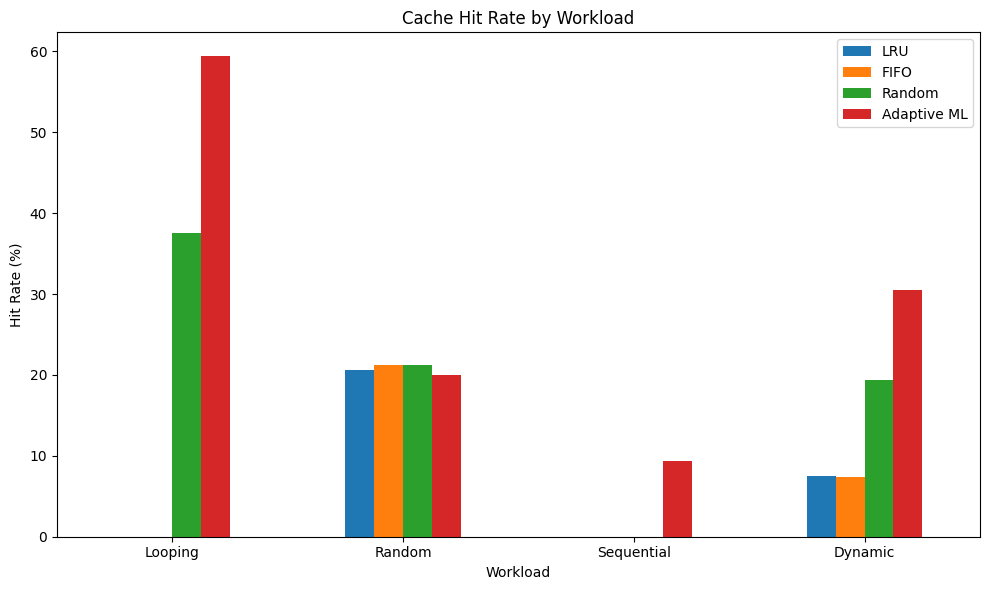

In [54]:
import matplotlib.pyplot as plt

workload_comparison.set_index("Workload").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Hit Rate (%)")
plt.title("Cache Hit Rate by Workload")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

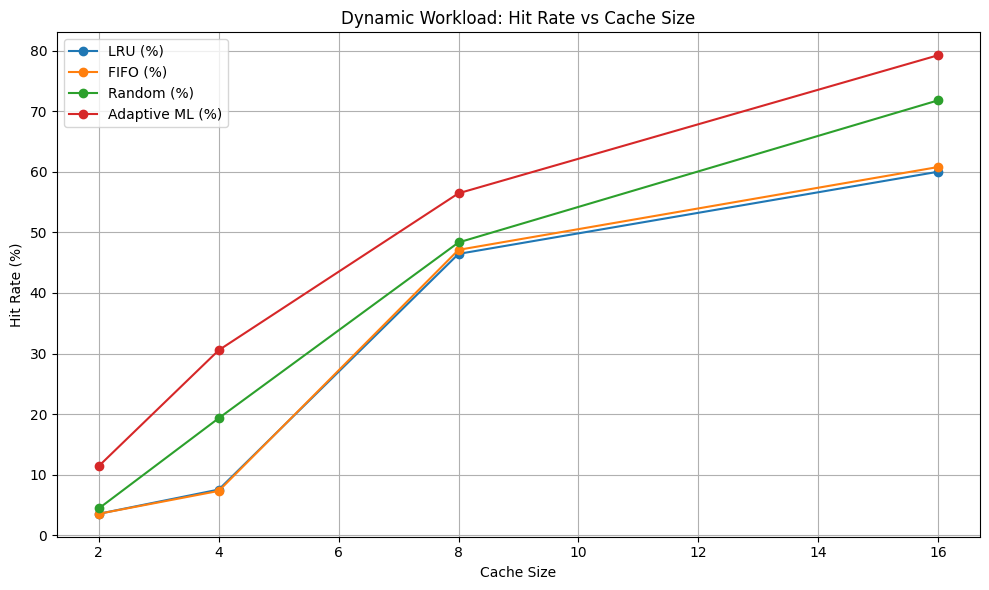

In [55]:
dynamic_results = size_comparison[
    size_comparison["Workload"] == "Dynamic"
].set_index("Cache Size")

dynamic_results[
    ["LRU (%)", "FIFO (%)", "Random (%)", "Adaptive ML (%)"]
].plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

plt.xlabel("Cache Size")
plt.ylabel("Hit Rate (%)")
plt.title("Dynamic Workload: Hit Rate vs Cache Size")
plt.grid(True)
plt.tight_layout()
plt.show()

In [56]:
from collections import defaultdict, Counter

In [57]:
def build_markov_prefetch_model(traces, context_size=2):
    transition_counts = defaultdict(Counter)

    for trace in traces:

        if len(trace) <= context_size:
            continue

        for i in range(context_size, len(trace)):

            context = tuple(
                trace[i - context_size:i]
            )

            next_block = trace[i]

            transition_counts[context][next_block] += 1

    return transition_counts

In [58]:
prefetch_model = build_markov_prefetch_model(
    train_traces,
    context_size=2
)

print("✅ Prefetch model trained!")
print("Number of learned contexts:", len(prefetch_model))

✅ Prefetch model trained!
Number of learned contexts: 407


In [59]:
def get_prediction(context, transition_counts):

    context = tuple(context)

    if context not in transition_counts:
        return None, 0.0

    candidates = transition_counts[context]

    total = sum(candidates.values())

    predicted_block, count = candidates.most_common(1)[0]

    probability = count / total

    return predicted_block, probability

In [60]:
test_contexts = [
    ("A", "B"),
    ("B", "C"),
    ("C", "A")
]

for context in test_contexts:

    prediction, probability = get_prediction(
        context,
        prefetch_model
    )

    print(
        f"{context} → "
        f"{prediction} "
        f"({probability:.2%})"
    )

('A', 'B') → C (99.20%)
('B', 'C') → D (98.73%)
('C', 'A') → B (33.33%)


In [61]:
def predict_prefetch(
    recent_sequence,
    model,
    threshold=0.70
):

    prediction, probability = get_prediction(
        recent_sequence,
        model
    )

    if prediction is None:
        return None, probability

    if probability >= threshold:
        return prediction, probability

    return None, probability

In [62]:
prediction, confidence = predict_prefetch(
    ("A", "B"),
    prefetch_model,
    threshold=0.70
)

print("Prediction :", prediction)
print("Confidence :", f"{confidence:.2%}")

Prediction : C
Confidence : 99.20%


In [63]:
class MarkovPrefetcher:
    def __init__(
        self,
        transition_model,
        context_size=2,
        threshold=0.70
    ):
        self.model = transition_model
        self.context_size = context_size
        self.threshold = threshold

    def predict(self, history):

        if len(history) < self.context_size:
            return None, 0.0

        context = tuple(
            history[-self.context_size:]
        )

        return predict_prefetch(
            context,
            self.model,
            self.threshold
        )

In [64]:
class MLReplacementPrefetchCache:
    def __init__(
        self,
        replacement_model,
        prefetcher,
        capacity=4
    ):

        self.replacement_model = replacement_model
        self.prefetcher = prefetcher

        self.capacity = capacity

        self.cache = []

        # History
        self.history = deque(maxlen=16)

        # Replacement state
        self.last_access = {}
        self.first_access = {}
        self.frequency = Counter()
        self.reuse_intervals = defaultdict(list)

        self.recent_history = deque(maxlen=16)
        self.recent_counter = Counter()

        # CPU performance
        self.hits = 0
        self.misses = 0
        self.evictions = 0

        # Prefetch metrics
        self.total_prefetches = 0
        self.useful_prefetches = 0
        self.useless_prefetches = 0

        # Track where blocks came from
        self.prefetched_blocks = set()

        # Events for frontend
        self.events = []

In [65]:
    def get_features(self, candidate, current_index):

        recency = (
            current_index -
            self.last_access[candidate]
        )

        freq = self.frequency[candidate]

        recent_freq = (
            self.recent_counter[candidate]
        )

        recent_ratio = (
            recent_freq / max(freq, 1)
        )

        intervals = self.reuse_intervals[candidate]

        if intervals:
            avg_reuse_distance = float(
                np.mean(intervals)
            )

            reuse_std = float(
                np.std(intervals)
            )
        else:
            avg_reuse_distance = float(recency)
            reuse_std = 0.0

        lifetime = (
            current_index -
            self.first_access[candidate]
        )

        recent_working_set_size = (
            len(self.recent_counter)
        )

        return {
            "recency": recency,
            "frequency": freq,
            "recent_frequency": recent_freq,
            "recent_frequency_ratio": recent_ratio,
            "avg_reuse_distance": avg_reuse_distance,
            "reuse_distance_std": reuse_std,
            "lifetime": lifetime,
            "recent_working_set_size":
                recent_working_set_size
        }

In [66]:
    def choose_victim(self, current_index):

        feature_rows = []

        for block in self.cache:

            feature_rows.append(
                self.get_features(
                    block,
                    current_index
                )
            )

        feature_df = pd.DataFrame(
            feature_rows
        )[REGRESSION_FEATURES]

        predicted_distances = (
            self.replacement_model.predict(
                feature_df
            )
        )

        victim_index = np.argmax(
            predicted_distances
        )

        victim = self.cache[victim_index]

        scores = {
            block: float(distance)
            for block, distance in zip(
                self.cache,
                predicted_distances
            )
        }

        return victim, scores

In [67]:
    def update_history(self, block, index):

        if block in self.last_access:

            interval = (
                index -
                self.last_access[block]
            )

            self.reuse_intervals[
                block
            ].append(interval)

        else:

            self.first_access[block] = index

        self.last_access[block] = index

        self.frequency[block] += 1

        # Maintain recent history
        if len(self.recent_history) == 16:

            old_block = (
                self.recent_history[0]
            )

            self.recent_counter[
                old_block
            ] -= 1

            if (
                self.recent_counter[
                    old_block
                ] <= 0
            ):

                del self.recent_counter[
                    old_block
                ]

        self.recent_history.append(block)

        self.recent_counter[block] += 1

In [68]:
    def access(self, block, index):

        cache_before = self.cache.copy()

        # -------------------------
        # CPU CACHE HIT
        # -------------------------

        if block in self.cache:

            self.hits += 1

            # Was this block brought by prefetching?
            if block in self.prefetched_blocks:

                self.useful_prefetches += 1
                self.prefetched_blocks.remove(block)

            self.history.append(block)

            self.update_history(
                block,
                index
            )

            event = {
                "index": index,
                "request": block,
                "result": "HIT",
                "cache_before": cache_before,
                "cache_after": self.cache.copy(),
                "evicted": None,
                "prefetched": False,
                "prefetch_prediction": None
            }

            self.events.append(event)

            return event

        # -------------------------
        # CPU CACHE MISS
        # -------------------------

        self.misses += 1

        # If cache is full, use ML replacement
        evicted = None
        replacement_scores = None

        if len(self.cache) >= self.capacity:

            evicted, replacement_scores = (
                self.choose_victim(index)
            )

            self.cache.remove(evicted)

            self.evictions += 1

            # If evicted block had been prefetched
            if evicted in self.prefetched_blocks:

                self.useless_prefetches += 1

                self.prefetched_blocks.remove(
                    evicted
                )

        # Bring requested block into cache
        self.cache.append(block)

        self.history.append(block)

        self.update_history(
            block,
            index
        )

        # -------------------------
        # PREFETCH PREDICTION
        # -------------------------

        prediction, confidence = (
            self.prefetcher.predict(
                list(self.history)
            )
        )

        prefetched = False

        # Don't prefetch if prediction is already cached
        if (
            prediction is not None
            and prediction not in self.cache
        ):

            # Make room if necessary
            if len(self.cache) >= self.capacity:

                victim, replacement_scores = (
                    self.choose_victim(index)
                )

                self.cache.remove(victim)

                self.evictions += 1

                if victim in self.prefetched_blocks:

                    self.useless_prefetches += 1

                    self.prefetched_blocks.remove(
                        victim
                    )

            # Insert prediction
            self.cache.append(prediction)

            self.prefetched_blocks.add(prediction)

            self.total_prefetches += 1

            prefetched = True

        event = {
            "index": index,
            "request": block,
            "result": "MISS",
            "cache_before": cache_before,
            "cache_after": self.cache.copy(),
            "evicted": evicted,

            "prefetched": prefetched,
            "prefetch_prediction": prediction,
            "prefetch_confidence": confidence,

            "replacement_scores":
                replacement_scores
        }

        self.events.append(event)

        return event

In [69]:
    def run(self, trace):

        for i, block in enumerate(trace):

            self.access(block, i)

        total_accesses = (
            self.hits +
            self.misses
        )

        prefetch_accuracy = (
            self.useful_prefetches /
            self.total_prefetches
            if self.total_prefetches > 0
            else 0
        )

        prefetch_coverage = (
            self.useful_prefetches /
            self.misses
            if self.misses > 0
            else 0
        )

        return {
            "hits": self.hits,
            "misses": self.misses,

            "hit_rate":
                self.hits / total_accesses,

            "miss_rate":
                self.misses / total_accesses,

            "evictions":
                self.evictions,

            "total_prefetches":
                self.total_prefetches,

            "useful_prefetches":
                self.useful_prefetches,

            "useless_prefetches":
                self.useless_prefetches,

            "prefetch_accuracy":
                prefetch_accuracy,

            "prefetch_coverage":
                prefetch_coverage,

            "events":
                self.events
        }

In [74]:
def get_features(self, candidate, current_index):

    # -----------------------------------------
    # Handle blocks that were prefetched
    # but have not yet been accessed by CPU
    # -----------------------------------------

    if candidate not in self.last_access:

        return {
            "recency": 0,
            "frequency": 0,
            "recent_frequency": 0,
            "recent_frequency_ratio": 0.0,
            "avg_reuse_distance": 0.0,
            "reuse_distance_std": 0.0,
            "lifetime": 0,
            "recent_working_set_size":
                len(self.recent_counter)
        }

    # -----------------------------------------
    # Normal CPU-accessed block
    # -----------------------------------------

    recency = (
        current_index -
        self.last_access[candidate]
    )

    freq = self.frequency[candidate]

    recent_freq = (
        self.recent_counter[candidate]
    )

    recent_ratio = (
        recent_freq / max(freq, 1)
    )

    intervals = self.reuse_intervals[candidate]

    if intervals:

        avg_reuse_distance = float(
            np.mean(intervals)
        )

        reuse_std = float(
            np.std(intervals)
        )

    else:

        avg_reuse_distance = float(recency)
        reuse_std = 0.0

    lifetime = (
        current_index -
        self.first_access[candidate]
    )

    recent_working_set_size = (
        len(self.recent_counter)
    )

    return {
        "recency": recency,
        "frequency": freq,
        "recent_frequency": recent_freq,
        "recent_frequency_ratio": recent_ratio,
        "avg_reuse_distance":
            avg_reuse_distance,
        "reuse_distance_std":
            reuse_std,
        "lifetime": lifetime,
        "recent_working_set_size":
            recent_working_set_size
    }

In [75]:
combined_result = combined_cache.run(
    dynamic_trace
)

print("🚀 ML REPLACEMENT + PREFETCHING")
print("--------------------------------")
print("Hits               :", combined_result["hits"])
print("Misses             :", combined_result["misses"])
print(
    "Hit Rate           :",
    f"{combined_result['hit_rate'] * 100:.2f}%"
)
print(
    "Miss Rate          :",
    f"{combined_result['miss_rate'] * 100:.2f}%"
)
print("Evictions          :", combined_result["evictions"])
print("Total Prefetches   :", combined_result["total_prefetches"])
print("Useful Prefetches  :", combined_result["useful_prefetches"])
print("Useless Prefetches :", combined_result["useless_prefetches"])
print(
    "Prefetch Accuracy  :",
    f"{combined_result['prefetch_accuracy'] * 100:.2f}%"
)
print(
    "Prefetch Coverage  :",
    f"{combined_result['prefetch_coverage'] * 100:.2f}%"
)

KeyError: 'I'

In [76]:
def patched_get_features(self, candidate, current_index):

    # Prefetched but never accessed by CPU
    if candidate not in self.last_access:

        return {
            "recency": 0,
            "frequency": 0,
            "recent_frequency": 0,
            "recent_frequency_ratio": 0.0,
            "avg_reuse_distance": 0.0,
            "reuse_distance_std": 0.0,
            "lifetime": 0,
            "recent_working_set_size": len(self.recent_counter)
        }

    recency = current_index - self.last_access[candidate]

    freq = self.frequency[candidate]

    recent_freq = self.recent_counter[candidate]

    recent_ratio = recent_freq / max(freq, 1)

    intervals = self.reuse_intervals[candidate]

    if intervals:
        avg_reuse_distance = float(np.mean(intervals))
        reuse_std = float(np.std(intervals))
    else:
        avg_reuse_distance = float(recency)
        reuse_std = 0.0

    lifetime = current_index - self.first_access[candidate]

    recent_working_set_size = len(self.recent_counter)

    return {
        "recency": recency,
        "frequency": freq,
        "recent_frequency": recent_freq,
        "recent_frequency_ratio": recent_ratio,
        "avg_reuse_distance": avg_reuse_distance,
        "reuse_distance_std": reuse_std,
        "lifetime": lifetime,
        "recent_working_set_size": recent_working_set_size
    }


# Patch the existing class directly
MLReplacementPrefetchCache.get_features = patched_get_features

print("✅ get_features() patched successfully!")

✅ get_features() patched successfully!


In [77]:
prefetcher = MarkovPrefetcher(
    transition_model=prefetch_model,
    context_size=2,
    threshold=0.70
)

combined_cache = MLReplacementPrefetchCache(
    replacement_model=regression_model,
    prefetcher=prefetcher,
    capacity=4
)

print("✅ Fresh combined cache created!")

✅ Fresh combined cache created!


In [78]:
small_trace = dynamic_trace[:30]

test_cache = MLReplacementPrefetchCache(
    replacement_model=regression_model,
    prefetcher=prefetcher,
    capacity=4
)

test_result = test_cache.run(small_trace)

print("✅ Small test completed!")
print("Hits   :", test_result["hits"])
print("Misses :", test_result["misses"])

✅ Small test completed!
Hits   : 17
Misses : 13


In [79]:
combined_result = combined_cache.run(dynamic_trace)

print("🚀 ML REPLACEMENT + PREFETCHING")
print("--------------------------------")
print("Hits               :", combined_result["hits"])
print("Misses             :", combined_result["misses"])
print(
    "Hit Rate           :",
    f"{combined_result['hit_rate'] * 100:.2f}%"
)
print(
    "Miss Rate          :",
    f"{combined_result['miss_rate'] * 100:.2f}%"
)
print("Evictions          :", combined_result["evictions"])
print("Total Prefetches   :", combined_result["total_prefetches"])
print("Useful Prefetches  :", combined_result["useful_prefetches"])
print("Useless Prefetches :", combined_result["useless_prefetches"])
print(
    "Prefetch Accuracy  :",
    f"{combined_result['prefetch_accuracy'] * 100:.2f}%"
)
print(
    "Prefetch Coverage  :",
    f"{combined_result['prefetch_coverage'] * 100:.2f}%"
)

🚀 ML REPLACEMENT + PREFETCHING
--------------------------------
Hits               : 405
Misses             : 495
Hit Rate           : 45.00%
Miss Rate          : 55.00%
Evictions          : 635
Total Prefetches   : 144
Useful Prefetches  : 132
Useless Prefetches : 12
Prefetch Accuracy  : 91.67%
Prefetch Coverage  : 26.67%


In [80]:
phase4_results = []

for workload_name, trace in workloads.items():

    # -----------------------------
    # LRU
    # -----------------------------
    lru = LRUCache(capacity=4).run(trace)

    # -----------------------------
    # FIFO
    # -----------------------------
    fifo = FIFOCache(capacity=4).run(trace)

    # -----------------------------
    # Random
    # -----------------------------
    rnd = RandomCache(
        capacity=4,
        seed=42
    ).run(trace)

    # -----------------------------
    # ML Replacement only
    # -----------------------------
    ml_replace = AdaptiveMLCacheV3(
        model=regression_model,
        capacity=4,
        recent_window=16
    ).run(trace)

    # -----------------------------
    # ML Replacement + Prefetch
    # -----------------------------
    prefetcher = MarkovPrefetcher(
        transition_model=prefetch_model,
        context_size=2,
        threshold=0.70
    )

    combined = MLReplacementPrefetchCache(
        replacement_model=regression_model,
        prefetcher=prefetcher,
        capacity=4
    ).run(trace)

    phase4_results.append({

        "Workload": workload_name,

        "LRU Hit Rate (%)":
            lru["hit_rate"] * 100,

        "FIFO Hit Rate (%)":
            fifo["hit_rate"] * 100,

        "Random Hit Rate (%)":
            rnd["hit_rate"] * 100,

        "ML Replacement (%)":
            ml_replace["hit_rate"] * 100,

        "ML + Prefetch (%)":
            combined["hit_rate"] * 100,

        "Prefetch Accuracy (%)":
            combined["prefetch_accuracy"] * 100,

        "Prefetch Coverage (%)":
            combined["prefetch_coverage"] * 100,

        "Total Prefetches":
            combined["total_prefetches"],

        "Useful Prefetches":
            combined["useful_prefetches"],

        "Useless Prefetches":
            combined["useless_prefetches"]
    })


phase4_comparison = pd.DataFrame(
    phase4_results
)

display(
    phase4_comparison.round(2)
)

,Workload,LRU Hit Rate (%),FIFO Hit Rate (%),Random Hit Rate (%),ML Replacement (%),ML + Prefetch (%),Prefetch Accuracy (%),Prefetch Coverage (%),Total Prefetches,Useful Prefetches,Useless Prefetches
0,Looping,0.00,0.00,37.60,59.40,59.8,100.00,1.49,3,3,0
1,Random,20.60,21.20,21.20,20.00,20.8,50.00,2.02,16,8,8
2,Sequential,0.00,0.00,0.00,9.40,52.8,98.64,91.95,220,217,3
3,Dynamic,7.56,7.33,19.33,30.56,45.0,91.67,26.67,144,132,12


In [81]:
def choose_victim_excluding(self, current_index, excluded_blocks):

    candidates = [
        block
        for block in self.cache
        if block not in excluded_blocks
    ]

    # If nothing is available, return None
    if not candidates:
        return None, {}

    feature_rows = []

    for block in candidates:
        feature_rows.append(
            self.get_features(
                block,
                current_index
            )
        )

    feature_df = pd.DataFrame(
        feature_rows
    )[REGRESSION_FEATURES]

    predicted_distances = (
        self.replacement_model.predict(
            feature_df
        )
    )

    victim_index = np.argmax(
        predicted_distances
    )

    victim = candidates[victim_index]

    scores = {
        block: float(distance)
        for block, distance in zip(
            candidates,
            predicted_distances
        )
    }

    return victim, scores

In [84]:
def choose_victim_excluding(self, current_index, excluded_blocks):

    candidates = [
        block
        for block in self.cache
        if block not in excluded_blocks
    ]

    if not candidates:
        return None, {}

    feature_rows = []

    for block in candidates:
        feature_rows.append(
            self.get_features(block, current_index)
        )

    feature_df = pd.DataFrame(
        feature_rows
    )[REGRESSION_FEATURES]

    predicted_distances = self.replacement_model.predict(
        feature_df
    )

    victim_index = np.argmax(predicted_distances)
    victim = candidates[victim_index]

    scores = {
        block: float(distance)
        for block, distance in zip(
            candidates,
            predicted_distances
        )
    }

    return victim, scores


# Attach the method to our existing class
MLReplacementPrefetchCache.choose_victim_excluding = choose_victim_excluding

print("✅ choose_victim_excluding() added!")

✅ choose_victim_excluding() added!


In [85]:
def patched_access(self, block, index):

    cache_before = self.cache.copy()

    # ============================================
    # CACHE HIT
    # ============================================

    if block in self.cache:

        self.hits += 1

        was_prefetched = (
            block in self.prefetched_blocks
        )

        if was_prefetched:
            self.useful_prefetches += 1
            self.prefetched_blocks.remove(block)

        self.update_history(block, index)

        event = {
            "index": index,
            "request": block,
            "result": "HIT",
            "cache_before": cache_before,
            "cache_after": self.cache.copy(),
            "evicted": None,
            "prefetched": was_prefetched,
            "prefetch_prediction": None,
            "prefetch_confidence": None,
            "replacement_scores": None
        }

        self.events.append(event)

        return event

    # ============================================
    # CACHE MISS
    # ============================================

    self.misses += 1

    evicted = None
    replacement_scores = None

    # --------------------------------------------
    # Bring CPU-requested block into cache
    # --------------------------------------------

    if len(self.cache) >= self.capacity:

        evicted, replacement_scores = (
            self.choose_victim(index)
        )

        self.cache.remove(evicted)

        self.evictions += 1

        if evicted in self.prefetched_blocks:

            self.useless_prefetches += 1

            self.prefetched_blocks.remove(evicted)

    self.cache.append(block)

    # IMPORTANT:
    # Requested CPU block is now protected.
    self.update_history(block, index)

    # ============================================
    # PREFETCH
    # ============================================

    prediction, confidence = (
        self.prefetcher.predict(
            list(self.recent_history)
        )
    )

    prefetched = False
    prefetch_eviction = None

    if (
        prediction is not None
        and prediction not in self.cache
    ):

        # Need room for predicted block
        if len(self.cache) >= self.capacity:

            # IMPORTANT:
            # Never evict the block the CPU
            # just requested.
            victim, prefetch_scores = (
                self.choose_victim_excluding(
                    index,
                    excluded_blocks={block}
                )
            )

            if victim is not None:

                self.cache.remove(victim)

                self.evictions += 1

                prefetch_eviction = victim

                if victim in self.prefetched_blocks:

                    self.useless_prefetches += 1

                    self.prefetched_blocks.remove(
                        victim
                    )

        # Insert prefetched block
        if prediction not in self.cache:

            self.cache.append(prediction)

            self.prefetched_blocks.add(
                prediction
            )

            self.total_prefetches += 1

            prefetched = True

    event = {
        "index": index,
        "request": block,
        "result": "MISS",

        "cache_before": cache_before,
        "cache_after": self.cache.copy(),

        "evicted": evicted,

        "prefetched": prefetched,
        "prefetch_prediction": prediction,
        "prefetch_confidence": confidence,

        "replacement_scores":
            replacement_scores,

        "prefetch_eviction":
            prefetch_eviction
    }

    self.events.append(event)

    return event


# Replace the old access method
MLReplacementPrefetchCache.access = patched_access

print("✅ access() patched successfully!")

✅ access() patched successfully!


In [86]:
prefetcher = MarkovPrefetcher(
    transition_model=prefetch_model,
    context_size=2,
    threshold=0.70
)

combined_cache = MLReplacementPrefetchCache(
    replacement_model=regression_model,
    prefetcher=prefetcher,
    capacity=4
)

print("✅ Fresh cache created!")

✅ Fresh cache created!


In [87]:
small_trace = dynamic_trace[:30]

test_cache = MLReplacementPrefetchCache(
    replacement_model=regression_model,
    prefetcher=prefetcher,
    capacity=4
)

test_result = test_cache.run(small_trace)

print("✅ 30-access test completed")
print("Hits   :", test_result["hits"])
print("Misses :", test_result["misses"])

✅ 30-access test completed
Hits   : 17
Misses : 13


In [88]:
combined_result = combined_cache.run(
    dynamic_trace
)

print("🚀 ML REPLACEMENT + PREFETCHING")
print("--------------------------------")
print("Hits               :", combined_result["hits"])
print("Misses             :", combined_result["misses"])
print(
    "Hit Rate           :",
    f"{combined_result['hit_rate'] * 100:.2f}%"
)
print(
    "Miss Rate          :",
    f"{combined_result['miss_rate'] * 100:.2f}%"
)
print("Evictions          :", combined_result["evictions"])
print("Total Prefetches   :", combined_result["total_prefetches"])
print("Useful Prefetches  :", combined_result["useful_prefetches"])
print("Useless Prefetches :", combined_result["useless_prefetches"])
print(
    "Prefetch Accuracy  :",
    f"{combined_result['prefetch_accuracy'] * 100:.2f}%"
)
print(
    "Prefetch Coverage  :",
    f"{combined_result['prefetch_coverage'] * 100:.2f}%"
)

🚀 ML REPLACEMENT + PREFETCHING
--------------------------------
Hits               : 402
Misses             : 498
Hit Rate           : 44.67%
Miss Rate          : 55.33%
Evictions          : 642
Total Prefetches   : 148
Useful Prefetches  : 139
Useless Prefetches : 9
Prefetch Accuracy  : 93.92%
Prefetch Coverage  : 27.91%


In [89]:
phase4_final_results = []

for workload_name, trace in workloads.items():

    lru = LRUCache(capacity=4).run(trace)

    fifo = FIFOCache(capacity=4).run(trace)

    rnd = RandomCache(
        capacity=4,
        seed=42
    ).run(trace)

    ml_replace = AdaptiveMLCacheV3(
        model=regression_model,
        capacity=4,
        recent_window=16
    ).run(trace)

    prefetcher = MarkovPrefetcher(
        transition_model=prefetch_model,
        context_size=2,
        threshold=0.70
    )

    combined = MLReplacementPrefetchCache(
        replacement_model=regression_model,
        prefetcher=prefetcher,
        capacity=4
    ).run(trace)

    phase4_final_results.append({
        "Workload": workload_name,

        "LRU (%)":
            lru["hit_rate"] * 100,

        "FIFO (%)":
            fifo["hit_rate"] * 100,

        "Random (%)":
            rnd["hit_rate"] * 100,

        "ML Replacement (%)":
            ml_replace["hit_rate"] * 100,

        "ML + Prefetch (%)":
            combined["hit_rate"] * 100,

        "Prefetch Accuracy (%)":
            combined["prefetch_accuracy"] * 100,

        "Prefetch Coverage (%)":
            combined["prefetch_coverage"] * 100,

        "Total Prefetches":
            combined["total_prefetches"],

        "Useful Prefetches":
            combined["useful_prefetches"],

        "Useless Prefetches":
            combined["useless_prefetches"]
    })

phase4_final = pd.DataFrame(phase4_final_results)

display(phase4_final.round(2))

,Workload,LRU (%),FIFO (%),Random (%),ML Replacement (%),ML + Prefetch (%),Prefetch Accuracy (%),Prefetch Coverage (%),Total Prefetches,Useful Prefetches,Useless Prefetches
0,Looping,0.00,0.00,37.60,59.40,59.80,100.00,1.49,3,3,0
1,Random,20.60,21.20,21.20,20.00,21.00,58.82,2.53,17,10,7
2,Sequential,0.00,0.00,0.00,9.40,52.80,98.70,96.19,230,227,3
3,Dynamic,7.56,7.33,19.33,30.56,44.67,93.92,27.91,148,139,9


In [90]:
phase4_final.to_csv(
    "phase4_final_results.csv",
    index=False
)

print("✅ Phase 4 final results saved")

✅ Phase 4 final results saved


In [91]:
from collections import Counter
import numpy as np


def distribution(window):
    counts = Counter(window)
    total = len(window)

    return {
        block: count / total
        for block, count in counts.items()
    }


def js_divergence(window_a, window_b):
    """
    Jensen-Shannon divergence between two
    memory-access distributions.
    """

    dist_a = distribution(window_a)
    dist_b = distribution(window_b)

    blocks = set(dist_a) | set(dist_b)

    p = np.array([
        dist_a.get(block, 0.0)
        for block in blocks
    ])

    q = np.array([
        dist_b.get(block, 0.0)
        for block in blocks
    ])

    m = 0.5 * (p + q)

    def kl_divergence(x, y):
        mask = x > 0
        return np.sum(
            x[mask] *
            np.log2(
                x[mask] /
                np.maximum(y[mask], 1e-12)
            )
        )

    return (
        0.5 * kl_divergence(p, m) +
        0.5 * kl_divergence(q, m)
    )

In [92]:
def detect_phase_changes(
    trace,
    window_size=32,
    threshold=0.20
):

    changes = []

    for i in range(
        window_size,
        len(trace) - window_size,
        window_size
    ):

        previous_window = trace[
            i - window_size:i
        ]

        current_window = trace[
            i:i + window_size
        ]

        divergence = js_divergence(
            previous_window,
            current_window
        )

        if divergence >= threshold:

            changes.append({
                "index": i,
                "divergence": divergence
            })

    return changes

In [93]:
phase_changes = detect_phase_changes(
    dynamic_trace,
    window_size=32,
    threshold=0.20
)

print("Detected phase changes:")
for change in phase_changes[:20]:
    print(
        f"Index {change['index']} "
        f"→ divergence "
        f"{change['divergence']:.3f}"
    )

Detected phase changes:
Index 288 → divergence 0.203
Index 320 → divergence 0.426
Index 352 → divergence 0.280
Index 416 → divergence 0.363
Index 448 → divergence 0.292
Index 512 → divergence 0.262
Index 544 → divergence 0.275
Index 576 → divergence 0.237
Index 608 → divergence 0.297


In [94]:
def detect_phase_changes_v2(
    trace,
    window_size=32,
    threshold=0.25,
    consecutive_required=2,
    cooldown=128
):
    divergences = []

    # Calculate divergence between consecutive windows
    for i in range(
        window_size,
        len(trace) - window_size,
        window_size
    ):

        previous_window = trace[
            i - window_size:i
        ]

        current_window = trace[
            i:i + window_size
        ]

        divergence = js_divergence(
            previous_window,
            current_window
        )

        divergences.append({
            "index": i,
            "divergence": divergence
        })

    changes = []

    consecutive_count = 0
    cooldown_remaining = 0

    for item in divergences:

        if cooldown_remaining > 0:
            cooldown_remaining -= window_size
            consecutive_count = 0
            continue

        if item["divergence"] >= threshold:

            consecutive_count += 1

        else:

            consecutive_count = 0

        # Confirm a phase change only after
        # multiple consecutive high-divergence windows
        if consecutive_count >= consecutive_required:

            # Use the first high-divergence point
            change_index = (
                item["index"]
                - (
                    consecutive_required - 1
                ) * window_size
            )

            changes.append({
                "index": change_index,
                "divergence": item["divergence"]
            })

            # Prevent repeated detections
            cooldown_remaining = cooldown

            consecutive_count = 0

    return changes

In [95]:
phase_changes_v2 = detect_phase_changes_v2(
    dynamic_trace,
    window_size=32,
    threshold=0.25,
    consecutive_required=2,
    cooldown=128
)

print("Detected phase changes — V2")
print("=" * 50)

for change in phase_changes_v2:
    print(
        f"Index {change['index']} "
        f"→ divergence "
        f"{change['divergence']:.3f}"
    )

Detected phase changes — V2
Index 320 → divergence 0.280
Index 512 → divergence 0.275


In [96]:
from collections import Counter
import numpy as np


def workload_features(window):
    counts = Counter(window)
    n = len(window)

    # Number of distinct blocks
    unique_blocks = len(counts)

    # Fraction of accesses that belong to repeated blocks
    repeated_accesses = sum(
        count
        for count in counts.values()
        if count > 1
    )

    repetition_ratio = repeated_accesses / max(n, 1)

    return {
        "unique_blocks": unique_blocks,
        "repetition_ratio": repetition_ratio
    }


def detect_phase_changes_v3(
    trace,
    window_size=64,
    js_threshold=0.15,
    unique_change_threshold=0.30,
    repetition_change_threshold=0.20,
    cooldown_windows=3
):

    results = []

    cooldown = 0

    for i in range(
        window_size,
        len(trace) - window_size + 1,
        window_size
    ):

        previous = trace[
            i - window_size:i
        ]

        current = trace[
            i:i + window_size
        ]

        # -------------------------------
        # Signal 1: distribution change
        # -------------------------------

        js_score = js_divergence(
            previous,
            current
        )

        # -------------------------------
        # Signal 2: unique block change
        # -------------------------------

        prev_features = workload_features(
            previous
        )

        curr_features = workload_features(
            current
        )

        prev_unique = prev_features[
            "unique_blocks"
        ]

        curr_unique = curr_features[
            "unique_blocks"
        ]

        unique_change = (
            abs(curr_unique - prev_unique)
            / max(prev_unique, 1)
        )

        # -------------------------------
        # Signal 3: repetition change
        # -------------------------------

        prev_repeat = prev_features[
            "repetition_ratio"
        ]

        curr_repeat = curr_features[
            "repetition_ratio"
        ]

        repetition_change = abs(
            curr_repeat - prev_repeat
        )

        # -------------------------------
        # Combined change score
        # -------------------------------

        signals = 0

        if js_score >= js_threshold:
            signals += 1

        if unique_change >= unique_change_threshold:
            signals += 1

        if (
            repetition_change
            >= repetition_change_threshold
        ):
            signals += 1

        # Require at least 2 independent signals
        detected = signals >= 2

        if cooldown > 0:
            detected = False
            cooldown -= 1

        if detected:

            results.append({
                "index": i,
                "js_score": js_score,
                "unique_change": unique_change,
                "repetition_change":
                    repetition_change,
                "signals": signals
            })

            cooldown = cooldown_windows

    return results

In [97]:
phase_changes_v3 = detect_phase_changes_v3(
    dynamic_trace,
    window_size=64
)

print("Detected phase changes — V3")
print("=" * 70)

for change in phase_changes_v3:

    print(
        f"Index {change['index']} | "
        f"JSD={change['js_score']:.3f} | "
        f"Unique Change={change['unique_change']:.3f} | "
        f"Repeat Change={change['repetition_change']:.3f} | "
        f"Signals={change['signals']}"
    )

Detected phase changes — V3
Index 320 | JSD=0.358 | Unique Change=0.667 | Repeat Change=0.016 | Signals=2


In [98]:
from collections import defaultdict, Counter


class AdaptiveMarkovPrefetcher:

    def __init__(
        self,
        base_model,
        context_size=2,
        threshold=0.70,
        decay=0.90
    ):
        self.context_size = context_size
        self.threshold = threshold
        self.decay = decay

        # Copy the pretrained transition knowledge
        self.transition_counts = defaultdict(Counter)

        for context, counter in base_model.items():
            self.transition_counts[context].update(counter)

        # Track how much recent learning has happened
        self.updates = 0

    def decay_context(self, context):

        if context not in self.transition_counts:
            return

        for block in list(
            self.transition_counts[context].keys()
        ):
            self.transition_counts[context][block] *= self.decay

            if self.transition_counts[context][block] < 0.01:
                del self.transition_counts[context][block]

    def update(self, context, next_block):

        context = tuple(context)

        # Give older knowledge slightly less weight
        self.decay_context(context)

        # Strongly reinforce what just happened
        self.transition_counts[context][next_block] += 1.0

        self.updates += 1

    def predict(self, history):

        if len(history) < self.context_size:
            return None, 0.0

        context = tuple(
            history[-self.context_size:]
        )

        if context not in self.transition_counts:
            return None, 0.0

        candidates = self.transition_counts[context]

        total = sum(candidates.values())

        if total <= 0:
            return None, 0.0

        prediction, count = candidates.most_common(1)[0]

        confidence = count / total

        if confidence >= self.threshold:
            return prediction, confidence

        return None, confidence


print("✅ Adaptive Markov Prefetcher created!")

✅ Adaptive Markov Prefetcher created!


In [99]:
adaptive_prefetcher = AdaptiveMarkovPrefetcher(
    base_model=prefetch_model,
    context_size=2,
    threshold=0.70,
    decay=0.90
)

context = ("A", "B")

print("Before online learning:")
prediction, confidence = adaptive_prefetcher.predict(
    ["A", "B"]
)

print(
    f"A,B → {prediction} "
    f"({confidence:.2%})"
)

Before online learning:
A,B → C (99.20%)


In [100]:
for _ in range(20):
    adaptive_prefetcher.update(
        context=("A", "B"),
        next_block="D"
    )

print("\nAfter online learning:")
prediction, confidence = adaptive_prefetcher.predict(
    ["A", "B"]
)

print(
    f"A,B → {prediction} "
    f"({confidence:.2%})"
)


After online learning:
A,B → C (93.78%)


In [101]:
def run_adaptive_prefetch_test(
    trace,
    base_model,
    context_size=2,
    threshold=0.70,
    decay=0.90
):

    adaptive = AdaptiveMarkovPrefetcher(
        base_model=base_model,
        context_size=context_size,
        threshold=threshold,
        decay=decay
    )

    history = []

    predictions = []

    for i, block in enumerate(trace):

        # --------------------------------
        # Predict BEFORE seeing current block
        # --------------------------------

        prediction, confidence = adaptive.predict(
            history
        )

        predictions.append({
            "index": i,
            "actual": block,
            "prediction": prediction,
            "confidence": confidence
        })

        # --------------------------------
        # Now observe what actually happened
        # --------------------------------

        if len(history) >= context_size:

            context = tuple(
                history[-context_size:]
            )

            adaptive.update(
                context=context,
                next_block=block
            )

        history.append(block)

    return adaptive, predictions

In [102]:
adaptive_model, adaptive_predictions = (
    run_adaptive_prefetch_test(
        dynamic_trace,
        base_model=prefetch_model,
        context_size=2,
        threshold=0.70,
        decay=0.90
    )
)

print("✅ Online adaptive simulation completed!")

✅ Online adaptive simulation completed!


In [103]:
print("ADAPTIVE PREDICTIONS")
print("=" * 70)

for item in adaptive_predictions:

    if item["prediction"] is not None:

        if (
            item["index"] < 330
            or
            330 <= item["index"] < 370
            or
            590 <= item["index"] < 630
        ):

            print(
                f"Index {item['index']:3d} | "
                f"Actual={item['actual']} | "
                f"Predicted={item['prediction']} | "
                f"Confidence={item['confidence']:.2%}"
            )

ADAPTIVE PREDICTIONS
Index   2 | Actual=C | Predicted=C | Confidence=99.20%
Index   3 | Actual=D | Predicted=D | Confidence=98.73%
Index   4 | Actual=E | Predicted=E | Confidence=98.96%
Index   5 | Actual=F | Predicted=F | Confidence=99.20%
Index   6 | Actual=A | Predicted=A | Confidence=78.11%
Index   7 | Actual=B | Predicted=B | Confidence=98.29%
Index   8 | Actual=C | Predicted=C | Confidence=99.20%
Index   9 | Actual=D | Predicted=D | Confidence=98.73%
Index  10 | Actual=E | Predicted=E | Confidence=98.96%
Index  11 | Actual=F | Predicted=F | Confidence=99.20%
Index  12 | Actual=A | Predicted=A | Confidence=78.12%
Index  13 | Actual=B | Predicted=B | Confidence=98.30%
Index  14 | Actual=C | Predicted=C | Confidence=99.20%
Index  15 | Actual=D | Predicted=D | Confidence=98.73%
Index  16 | Actual=E | Predicted=E | Confidence=98.97%
Index  17 | Actual=F | Predicted=F | Confidence=99.20%
Index  18 | Actual=A | Predicted=A | Confidence=78.15%
Index  19 | Actual=B | Predicted=B | Confide

In [104]:
valid_predictions = [
    item
    for item in adaptive_predictions
    if item["prediction"] is not None
]

correct_predictions = [
    item
    for item in valid_predictions
    if item["prediction"] == item["actual"]
]

prediction_accuracy = (
    len(correct_predictions)
    / len(valid_predictions)
    if valid_predictions
    else 0
)

print("🔄 ONLINE ADAPTIVE PREFETCH")
print("---------------------------")
print(
    "Predictions made :",
    len(valid_predictions)
)
print(
    "Correct          :",
    len(correct_predictions)
)
print(
    "Accuracy         :",
    f"{prediction_accuracy * 100:.2f}%"
)

🔄 ONLINE ADAPTIVE PREFETCH
---------------------------
Predictions made : 603
Correct          : 585
Accuracy         : 97.01%


In [105]:
def phase_accuracy(
    predictions,
    start,
    end
):
    section = [
        item
        for item in predictions
        if start <= item["index"] < end
        and item["prediction"] is not None
    ]

    if not section:
        return 0, 0

    correct = sum(
        item["prediction"] == item["actual"]
        for item in section
    )

    return (
        len(section),
        correct / len(section)
    )


phases = {
    "Looping": (0, 300),
    "Random": (300, 600),
    "Sequential": (600, 900)
}

for name, (start, end) in phases.items():

    count, accuracy = phase_accuracy(
        adaptive_predictions,
        start,
        end
    )

    print(
        f"{name:12s} → "
        f"Predictions={count:3d}, "
        f"Accuracy={accuracy * 100:.2f}%"
    )

Looping      → Predictions=298, Accuracy=100.00%
Random       → Predictions= 17, Accuracy=5.88%
Sequential   → Predictions=288, Accuracy=99.31%


In [106]:
# ============================================================
# SAVE ALL TRAINED MODELS + CONFIGURATION
# ============================================================

import joblib
import json
from google.colab import files


# ------------------------------------------------------------
# 1. Save Replacement ML Model (V3)
# ------------------------------------------------------------

joblib.dump(
    regression_model,
    "replacement_regression_v3.pkl"
)


# ------------------------------------------------------------
# 2. Save Prefetch Transition Model
# ------------------------------------------------------------

joblib.dump(
    dict(prefetch_model),
    "prefetch_markov_model.pkl"
)


# ------------------------------------------------------------
# 3. Save Adaptive Prefetch Configuration
# ------------------------------------------------------------

adaptive_config = {
    "context_size": 2,
    "confidence_threshold": 0.70,
    "decay": 0.90,
    "replacement_features": REGRESSION_FEATURES,
    "replacement_model": "RandomForestRegressor",
    "prefetch_model": "Markov"
}

with open(
    "adaptive_cache_config.json",
    "w"
) as f:
    json.dump(
        adaptive_config,
        f,
        indent=4
    )


# ------------------------------------------------------------
# 4. Save Feature Names
# ------------------------------------------------------------

with open(
    "replacement_features.json",
    "w"
) as f:
    json.dump(
        REGRESSION_FEATURES,
        f,
        indent=4
    )


# ------------------------------------------------------------
# 5. Save Phase 4 Results
# ------------------------------------------------------------

phase4_final.to_csv(
    "phase4_final_results.csv",
    index=False
)


# ------------------------------------------------------------
# 6. Save Phase 3 Cache Results
# ------------------------------------------------------------

size_comparison.to_csv(
    "phase3_cache_size_results.csv",
    index=False
)

workload_comparison.to_csv(
    "phase3_workload_results.csv",
    index=False
)


# ------------------------------------------------------------
# 7. Display Saved Files
# ------------------------------------------------------------

saved_files = [
    "replacement_regression_v3.pkl",
    "prefetch_markov_model.pkl",
    "adaptive_cache_config.json",
    "replacement_features.json",
    "phase4_final_results.csv",
    "phase3_cache_size_results.csv",
    "phase3_workload_results.csv"
]

print("✅ ALL PROJECT FILES SAVED")
print("=" * 50)

for filename in saved_files:
    print(filename)

✅ ALL PROJECT FILES SAVED
replacement_regression_v3.pkl
prefetch_markov_model.pkl
adaptive_cache_config.json
replacement_features.json
phase4_final_results.csv
phase3_cache_size_results.csv
phase3_workload_results.csv


In [107]:
# Download trained replacement model
files.download("replacement_regression_v3.pkl")

# Download trained prefetch model
files.download("prefetch_markov_model.pkl")

# Download configuration
files.download("adaptive_cache_config.json")

# Download feature definitions
files.download("replacement_features.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

print("Training Random Forest...")
model.fit(X_train, y_train)

print("✅ Model training completed!")

Training Random Forest...
✅ Model training completed!


In [ ]:
y_val_pred = model.predict(X_val)

val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)
val_recall = recall_score(y_val, y_val_pred)
val_f1 = f1_score(y_val, y_val_pred)

print("VALIDATION RESULTS")
print("------------------")
print(f"Accuracy : {val_accuracy:.4f}")
print(f"Precision: {val_precision:.4f}")
print(f"Recall   : {val_recall:.4f}")
print(f"F1 Score : {val_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

VALIDATION RESULTS
------------------
Accuracy : 0.7550
Precision: 0.6876
Recall   : 0.6970
F1 Score : 0.6923

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.79      0.80     45845
           1       0.69      0.70      0.69     29982

    accuracy                           0.75     75827
   macro avg       0.74      0.74      0.74     75827
weighted avg       0.76      0.75      0.76     75827



In [ ]:
y_test_pred = model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

print("TEST RESULTS")
print("------------")
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1 Score : {test_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

TEST RESULTS
------------
Accuracy : 0.7504
Precision: 0.6821
Recall   : 0.6905
F1 Score : 0.6863

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.79      0.79     45934
           1       0.68      0.69      0.69     30039

    accuracy                           0.75     75973
   macro avg       0.74      0.74      0.74     75973
weighted avg       0.75      0.75      0.75     75973



In [ ]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=feature_columns
).sort_values(ascending=False)

print("Feature Importance:")
display(feature_importance)

Feature Importance:


,0
frequency,0.303897
recency,0.245777
cache_age,0.217914
reuse_distance,0.207384
recent_pattern,0.024973
previous_hit,0.000055


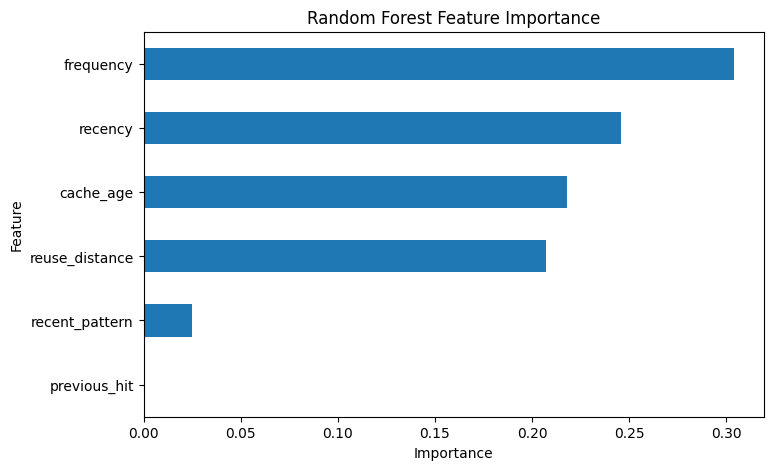

In [ ]:
plt.figure(figsize=(8, 5))
feature_importance.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.show()

In [ ]:
sample_scores = model.predict_proba(X_test.iloc[:10])[:, 1]

print("Sample future-use probabilities:")
for i, score in enumerate(sample_scores):
    print(f"Sample {i+1}: {score:.3f}")

Sample future-use probabilities:
Sample 1: 0.528
Sample 2: 0.524
Sample 3: 0.528
Sample 4: 0.528
Sample 5: 0.534
Sample 6: 0.524
Sample 7: 0.524
Sample 8: 0.526
Sample 9: 0.534
Sample 10: 0.528


In [ ]:
cache_features = pd.DataFrame({
    "recency": [2, 8, 3, 25],
    "frequency": [15, 5, 18, 1],
    "reuse_distance": [3, 10, 4, 40],
    "recent_pattern": [3, 1, 4, 0],
    "previous_hit": [1, 1, 1, 0],
    "cache_age": [2, 8, 3, 25]
}, index=["A", "B", "C", "D"])

scores = model.predict_proba(cache_features)[:, 1]

print("🤖 AI FUTURE-USE PREDICTIONS\n")

for block, score in zip(cache_features.index, scores):
    print(f"{block} → {score:.3f}")

eviction_candidate = cache_features.index[scores.argmin()]

print("\n🚨 AI DECISION")
print(f"Evict → {eviction_candidate}")

🤖 AI FUTURE-USE PREDICTIONS

A → 0.433
B → 0.334
C → 0.276
D → 0.694

🚨 AI DECISION
Evict → C


In [ ]:
import joblib

joblib.dump(model, "replacement_model.pkl")

print("✅ replacement_model.pkl saved successfully!")

✅ replacement_model.pkl saved successfully!


In [ ]:
from collections import Counter, defaultdict, deque
import numpy as np
import pandas as pd


def create_replacement_dataset_v2(
    trace,
    lookahead=8,
    recent_window=16
):
    rows = []

    last_access = {}
    first_access = {}
    frequency = Counter()
    reuse_intervals = defaultdict(list)

    recent_counter = Counter()
    recent_history = deque(maxlen=recent_window)

    for i, block in enumerate(trace):

        # --------------------------------------------------
        # FEATURES BEFORE CURRENT ACCESS
        # --------------------------------------------------

        for candidate in last_access:

            # 1. Recency
            recency = i - last_access[candidate]

            # 2. Total frequency
            freq = frequency[candidate]

            # 3. Frequency in recent window
            recent_freq = recent_counter[candidate]

            # 4. How much of its activity is recent?
            recent_ratio = recent_freq / max(freq, 1)

            # 5. Historical average reuse distance
            intervals = reuse_intervals[candidate]

            if intervals:
                avg_reuse_distance = float(np.mean(intervals))
                reuse_std = float(np.std(intervals))
            else:
                # First reuse hasn't happened yet
                avg_reuse_distance = float(recency)
                reuse_std = 0.0

            # 6. Lifetime of the block
            lifetime = i - first_access[candidate]

            # 7. Current workload's recent working-set size
            recent_working_set_size = len(recent_counter)

            # --------------------------------------------------
            # LABEL
            # --------------------------------------------------

            future_window = trace[
                i + 1 : i + 1 + lookahead
            ]

            will_reuse_soon = int(
                candidate in future_window
            )

            rows.append({
                "recency": recency,
                "frequency": freq,
                "recent_frequency": recent_freq,
                "recent_frequency_ratio": recent_ratio,
                "avg_reuse_distance": avg_reuse_distance,
                "reuse_distance_std": reuse_std,
                "lifetime": lifetime,
                "recent_working_set_size": recent_working_set_size,
                "will_reuse_soon": will_reuse_soon
            })

        # --------------------------------------------------
        # UPDATE HISTORY AFTER FEATURES ARE CREATED
        # --------------------------------------------------

        if block in last_access:

            interval = i - last_access[block]

            reuse_intervals[block].append(interval)

        else:
            first_access[block] = i

        last_access[block] = i
        frequency[block] += 1

        # Update recent window
        if len(recent_history) == recent_window:
            old_block = recent_history[0]
            recent_counter[old_block] -= 1

            if recent_counter[old_block] <= 0:
                del recent_counter[old_block]

        recent_history.append(block)
        recent_counter[block] += 1

    return pd.DataFrame(rows)

In [ ]:
replacement_v2 = create_replacement_dataset_v2(
    dynamic_trace,
    lookahead=8,
    recent_window=16
)

print("Dataset shape:", replacement_v2.shape)

display(replacement_v2.head())

print("\nLabel distribution:")
print(
    replacement_v2["will_reuse_soon"].value_counts()
)

Dataset shape: (15108, 9)


,recency,frequency,recent_frequency,recent_frequency_ratio,avg_reuse_distance,reuse_distance_std,lifetime,recent_working_set_size,will_reuse_soon
0,1,1,1,1.0,1.0,0.0,1,1,1
1,2,1,1,1.0,2.0,0.0,2,2,1
2,1,1,1,1.0,1.0,0.0,1,2,1
3,3,1,1,1.0,3.0,0.0,3,3,1
4,2,1,1,1.0,2.0,0.0,2,3,1



Label distribution:
will_reuse_soon
0    9123
1    5985
Name: count, dtype: int64


In [ ]:
train_v2 = pd.concat(
    [
        create_replacement_dataset_v2(trace)
        for trace in train_traces
    ],
    ignore_index=True
)

validation_v2 = pd.concat(
    [
        create_replacement_dataset_v2(trace)
        for trace in validation_traces
    ],
    ignore_index=True
)

test_v2 = pd.concat(
    [
        create_replacement_dataset_v2(trace)
        for trace in test_traces
    ],
    ignore_index=True
)

print("Train      :", train_v2.shape)
print("Validation :", validation_v2.shape)
print("Test       :", test_v2.shape)

Train      : (302879, 9)
Validation : (75827, 9)
Test       : (75973, 9)
